In [1]:
import torch
from torch import nn


In [2]:
# set the device the agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
import requests
from pathlib import Path 
import zipfile 

path = Path("Test_data")
image_path = path / "images"
zip_file = path / "images.zip"


if path.exists():
    print(f"{path} already exists, skipping download.")
else:
    print(f"{path} does not exist, downloading data.")
    path.mkdir(parents=True, exist_ok=True)
    url = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip"
    r = requests.get(url)
    with open(zip_file, "wb") as f:
        f.write(r.content)  

    with zipfile.ZipFile(zip_file, "r") as zip_ref:
        zip_ref.extractall(path)
        



Test_data already exists, skipping download.


In [4]:
from requests.api import request
import requests
import zipfile
from pathlib import Path

# Correct the typo in data_path: remove space
data_path = Path("data")
image_path = data_path / "pizza_steak_sushi"
zip_file_name = "pizza_steak_sushi.zip"

if image_path.is_dir():
  print(f"{image_path} directory exists.")
else:
  print(f"Did not find {image_path} directory, creating one...")
  # Create the image_path directory first
  image_path.mkdir(parents=True, exist_ok=True)

  # Define the full path for the zip file within the created directory
  zip_file_path = image_path / zip_file_name

  # Download the zip file
  print(f"Downloading {zip_file_name} data to {zip_file_path}...")
  # Correct the typo: requsts.get -> requests.get
  response = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")

  with open(zip_file_path, "wb") as f:
    f.write(response.content)

  # Unzip the file
  with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
    print(f"Unzipping {zip_file_name} data into {image_path}...")
    zip_ref.extractall(image_path)


data\pizza_steak_sushi directory exists.


In [5]:
import os
# create function to walk through our datasets
def walk_through_dir(dir_path):
  for dirpath,dirnames,filenames in os.walk(dir_path):
    print(f" there are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}' ")

In [6]:
walk_through_dir(image_path)

 there are 2 directories and 1 images in 'data\pizza_steak_sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\test' 
 there are 0 directories and 25 images in 'data\pizza_steak_sushi\test\pizza' 
 there are 0 directories and 19 images in 'data\pizza_steak_sushi\test\steak' 
 there are 0 directories and 31 images in 'data\pizza_steak_sushi\test\sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\train' 
 there are 0 directories and 78 images in 'data\pizza_steak_sushi\train\pizza' 
 there are 0 directories and 75 images in 'data\pizza_steak_sushi\train\steak' 
 there are 0 directories and 72 images in 'data\pizza_steak_sushi\train\sushi' 


In [7]:
# create train and test path
train_dir= image_path / "train"
test_dir= image_path / "test"
train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

Random image path: data\pizza_steak_sushi\train\sushi\3360207.jpg
Image class: sushi
Image height: 384
Image width: 512


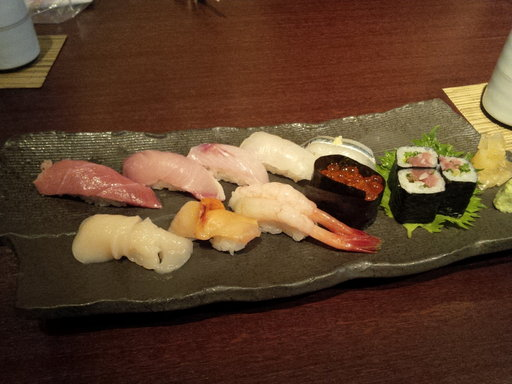

In [8]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# get all image paths
image_path_list=list(image_path.glob("*/*/*.jpg"))
# get a random image
random_image_path=random.choice(image_path_list)
# get the class of the image
image_class=random_image_path.parent.name
# open the image
img=Image.open(random_image_path)
img1=plt.imread(random_image_path)


# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img


In [ ]:
plt.imshow(img1)
plt.title(image_class)
plt.axis(False)

(np.float64(-0.5), np.float64(511.5), np.float64(383.5), np.float64(-0.5))

In [ ]:
# Transforming the data
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


In [ ]:
data_transform=transforms.Compose([
    # resize the image
    transforms.Resize(size=(64,64)),
    # Flip the images randomly on the horizontal for data augmentation
    transforms.RandomHorizontalFlip(p=0.5), # p = probability of flip, 0.5 = 50% chance
    # Turn the image into a torch.Tensor
    transforms.ToTensor()


])